In [1]:
print("Hello World!")

Hello World!


In [2]:
import sys
print(sys.executable)

C:\Users\Kishan\AppData\Local\Programs\Python\Python312\python.exe


In [3]:
import pandas as pd
print(pd.__version__)

2.2.2


In [4]:
import pandas as pd
df = pd.read_csv("../01_Structured Files/Amazon Product Reviews/amazon.csv")

In [5]:
df.head()

,Text,label
0,This is the best apps acording to a bunch of ...,1
1,This is a pretty good version of the game for ...,1
2,this is a really . there are a bunch of levels...,1
3,"This is a silly game and can be frustrating, b...",1
4,This is a terrific game on any pad. Hrs of fun...,1


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19996 entries, 0 to 19995
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Text    19996 non-null  object
 1   label   19996 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 312.6+ KB


In [7]:
df["label"].value_counts()

label
1    15230
0     4766
Name: count, dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df["Text"].head(10)

0    This is  the best apps acording to a bunch of ...
1    This is a pretty good version of the game for ...
2    this is a really . there are a bunch of levels...
3    This is a silly game and can be frustrating, b...
4    This is a terrific game on any pad. Hrs of fun...
5    This is a very entertaining game!  You don't h...
6    this is awesome and you don't need wi ti to pl...
7    this is awesome I bet no one even reads the re...
8    This is basicly the free version but with ads....
9    this is by far the best free app that is avail...
Name: Text, dtype: object

In [10]:
df["review_length"] = df["Text"].str.len()

In [11]:
df["review_length"].describe()

count    19996.000000
mean       175.787257
std         58.964840
min          3.000000
25%        123.000000
50%        164.000000
75%        254.000000
max        254.000000
Name: review_length, dtype: float64

In [12]:
(df["review_length"] == 254).sum()

np.int64(5084)

In [13]:
df["Text"].str.strip().eq("").sum()

np.int64(0)

In [14]:
df[df["label"] == 0]["Text"].head(5)

78    They call it three next mario??? Are the 'prof...
79    Angry People in my book!  Any moron who would ...
80    Argry Birds is for free to play a games on you...
81    cant stand this game. love the concept and pla...
82    Don't really know the point of this game.  It'...
Name: Text, dtype: object

In [15]:
df[df["label"] == 1]["Text"].head(5)

0    This is  the best apps acording to a bunch of ...
1    This is a pretty good version of the game for ...
2    this is a really . there are a bunch of levels...
3    This is a silly game and can be frustrating, b...
4    This is a terrific game on any pad. Hrs of fun...
Name: Text, dtype: object

In [16]:
df["label"].value_counts(normalize=True) * 100 

label
1    76.165233
0    23.834767
Name: proportion, dtype: float64

In [17]:
df.groupby("label")["review_length"].mean()

label
0    172.295006
1    176.880105
Name: review_length, dtype: float64

In [18]:
df["length_category"] = pd.cut(
    df["review_length"],
    bins=[0, 100, 200, 254],
    labels=["Short", "Medium", "Long"]
)

In [19]:
df["length_category"].value_counts()

length_category
Medium    11346
Long       7388
Short      1262
Name: count, dtype: int64

In [20]:
df.loc[df["review_length"].idxmin(), ["Text", "label", "review_length"]]

Text             fun
label              1
review_length      3
Name: 766, dtype: object

In [21]:
df.loc[df["review_length"].idxmax(), ["Text", "label", "review_length"]]

Text             This is the first app that I installed onKindl...
label                                                            1
review_length                                                  254
Name: 24, dtype: object

In [22]:
df.groupby("label")["review_length"].agg(["min" , "max" , "mean"])

,min,max,mean
label,,,
0,4,254,172.295006
1,3,254,176.880105


In [23]:
df["Text"].nunique()

19996

In [24]:
df.duplicated().sum()

np.int64(0)

In [25]:
df["Text"].nunique()

19996

In [26]:
df["Text"].str.lower().head()

0    this is  the best apps acording to a bunch of ...
1    this is a pretty good version of the game for ...
2    this is a really . there are a bunch of levels...
3    this is a silly game and can be frustrating, b...
4    this is a terrific game on any pad. hrs of fun...
Name: Text, dtype: object

In [27]:
df["clean_text"] = df["Text"].str.lower()

In [28]:
df[["Text","clean_text"]].head()

,Text,clean_text
0,This is the best apps acording to a bunch of ...,this is the best apps acording to a bunch of ...
1,This is a pretty good version of the game for ...,this is a pretty good version of the game for ...
2,this is a really . there are a bunch of levels...,this is a really . there are a bunch of levels...
3,"This is a silly game and can be frustrating, b...","this is a silly game and can be frustrating, b..."
4,This is a terrific game on any pad. Hrs of fun...,this is a terrific game on any pad. hrs of fun...


In [29]:
import string 
string.punctuation

'!"#$%&\'()*+,-./:;<=>?@[\\]^_`{|}~'

In [30]:
df["clean_text"] = df["clean_text"].str.replace(
    f"[{string.punctuation}]",
    "",
    regex=True
)

In [31]:
df[["Text", "clean_text"]].head()

,Text,clean_text
0,This is the best apps acording to a bunch of ...,this is the best apps acording to a bunch of ...
1,This is a pretty good version of the game for ...,this is a pretty good version of the game for ...
2,this is a really . there are a bunch of levels...,this is a really there are a bunch of levels ...
3,"This is a silly game and can be frustrating, b...",this is a silly game and can be frustrating bu...
4,This is a terrific game on any pad. Hrs of fun...,this is a terrific game on any pad hrs of fun ...


In [32]:
import nltk
nltk.download("stopwords")

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Kishan\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [33]:
%pip install nltk

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [34]:
import nltk

In [35]:
nltk.download("stopwords")

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Kishan\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [36]:
from nltk.corpus import stopwords
stop_words = set(stopwords.words("english"))

In [37]:
list(stop_words)[:20]

['and',
 'himself',
 'ours',
 'doesn',
 'other',
 'both',
 'mightn',
 'whom',
 'didn',
 'there',
 "needn't",
 'very',
 'under',
 'being',
 'why',
 'while',
 'a',
 'ma',
 "haven't",
 'shouldn']

In [38]:
df["final_text"] = df["clean_text"].apply(
    lambda text: " ".join(
        word for word in text.split()
        if word not in stop_words
    )
)

In [39]:
df[["Text", "clean_text", "final_text"]].head()

,Text,clean_text,final_text
0,This is the best apps acording to a bunch of ...,this is the best apps acording to a bunch of ...,best apps acording bunch people agree bombs eg...
1,This is a pretty good version of the game for ...,this is a pretty good version of the game for ...,pretty good version game free lots different l...
2,this is a really . there are a bunch of levels...,this is a really there are a bunch of levels ...,really bunch levels find golden eggs super fun
3,"This is a silly game and can be frustrating, b...",this is a silly game and can be frustrating bu...,silly game frustrating lots fun definitely rec...
4,This is a terrific game on any pad. Hrs of fun...,this is a terrific game on any pad hrs of fun ...,terrific game pad hrs fun grandkids love great...


In [40]:
all_words = " ".join(df["final_text"])

In [41]:
words = all_words.split()

In [42]:
len(words)

340336

In [43]:
from collections import Counter

word_counts = Counter(words)

In [44]:
word_counts.most_common(20)

[('app', 10652),
 ('game', 5834),
 ('great', 4015),
 ('love', 3958),
 ('like', 3903),
 ('use', 3251),
 ('get', 3203),
 ('kindle', 2888),
 ('one', 2631),
 ('fun', 2580),
 ('time', 2432),
 ('dont', 2420),
 ('free', 2207),
 ('really', 2194),
 ('would', 2051),
 ('easy', 2029),
 ('play', 2011),
 ('good', 1931),
 ('fire', 1929),
 ('works', 1637)]

In [45]:
positive_words = " ".join(
    df[df["label"] == 1]["final_text"]
).split()

In [46]:
positive_counts = Counter(positive_words)
positive_counts.most_common(20)

[('app', 8002),
 ('game', 4448),
 ('great', 3837),
 ('love', 3832),
 ('like', 3085),
 ('use', 2876),
 ('fun', 2325),
 ('kindle', 2162),
 ('get', 2153),
 ('one', 2114),
 ('easy', 1982),
 ('really', 1760),
 ('time', 1725),
 ('free', 1688),
 ('good', 1572),
 ('play', 1572),
 ('works', 1528),
 ('fire', 1449),
 ('dont', 1394),
 ('would', 1292)]

In [47]:
negative_words = " ".join(
    df[df["label"] == 0]["final_text"]
).split()

negative_counts = Counter(negative_words)

negative_counts.most_common(20)

[('app', 2650),
 ('game', 1386),
 ('get', 1050),
 ('dont', 1026),
 ('like', 818),
 ('would', 759),
 ('kindle', 726),
 ('time', 707),
 ('even', 665),
 ('work', 600),
 ('free', 519),
 ('one', 517),
 ('fire', 480),
 ('play', 439),
 ('really', 434),
 ('waste', 403),
 ('cant', 385),
 ('use', 375),
 ('download', 367),
 ('phone', 361)]

In [48]:
positive_total = len(positive_words)
negative_total = len(negative_words)

word_comparison = pd.DataFrame({
    "Positive_Count": pd.Series(positive_counts),
    "Negative_Count": pd.Series(negative_counts)
}).fillna(0)

word_comparison["Positive_%"] = (
    word_comparison["Positive_Count"] / positive_total * 100
)

word_comparison["Negative_%"] = (
    word_comparison["Negative_Count"] / negative_total * 100
)

word_comparison["Difference"] = (
    word_comparison["Positive_%"] -
    word_comparison["Negative_%"]
)

word_comparison.sort_values(
    "Difference",
    ascending=False
).head(20)

,Positive_Count,Negative_Count,Positive_%,Negative_%,Difference
love,3832.0,126.0,1.468542,0.158696,1.309846
great,3837.0,178.0,1.470459,0.224190,1.246269
easy,1982.0,47.0,0.759564,0.059196,0.700368
use,2876.0,375.0,1.102173,0.472310,0.629863
fun,2325.0,255.0,0.891013,0.321171,0.569842
works,1528.0,109.0,0.585577,0.137285,0.448293
best,1017.0,52.0,0.389746,0.065494,0.324253
well,1232.0,166.0,0.472141,0.209076,0.263065
alarm,843.0,55.0,0.323064,0.069272,0.253792
awesome,677.0,13.0,0.259448,0.016373,0.243074


In [49]:
word_comparison.sort_values(
    "Difference",
    ascending=True
).head(20)

,Positive_Count,Negative_Count,Positive_%,Negative_%,Difference
dont,1394.0,1026.0,0.534224,1.292240,-0.758016
work,563.0,600.0,0.215759,0.755696,-0.539937
get,2153.0,1050.0,0.825097,1.322468,-0.497371
even,889.0,665.0,0.340693,0.837563,-0.496870
waste,67.0,403.0,0.025676,0.507576,-0.481899
would,1292.0,759.0,0.495135,0.955956,-0.460821
didnt,290.0,332.0,0.111137,0.418152,-0.307015
doesnt,383.0,357.0,0.146778,0.449639,-0.302862
stupid,68.0,251.0,0.026060,0.316133,-0.290073
app,8002.0,2650.0,3.066617,3.337658,-0.271040


In [50]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


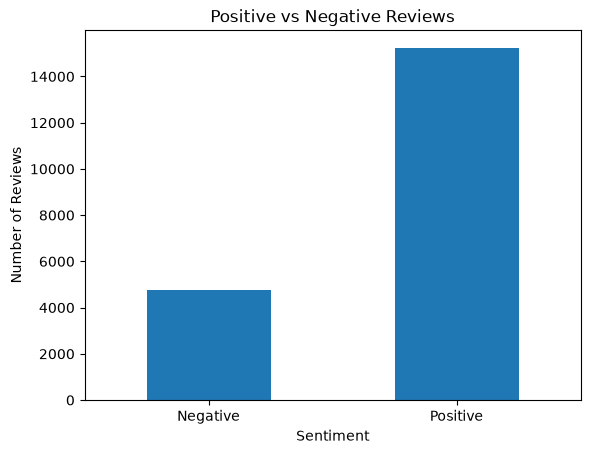

In [51]:
import matplotlib.pyplot as plt

df["label"].value_counts().sort_index().plot(
    kind="bar"
)

plt.title("Positive vs Negative Reviews")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.xticks([0, 1], ["Negative", "Positive"], rotation=0)
plt.show()

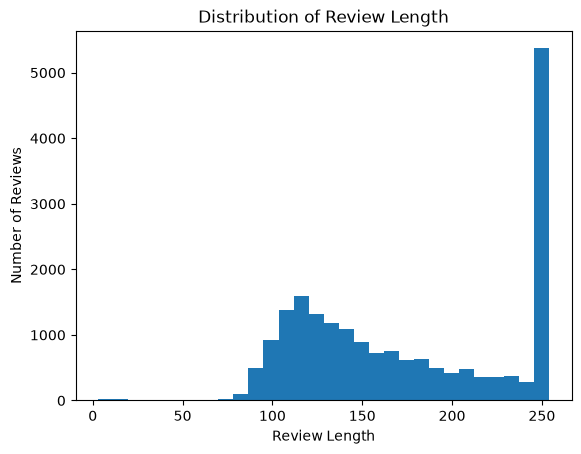

In [52]:
df["review_length"].plot(
    kind="hist",
    bins=30
)

plt.title("Distribution of Review Length")
plt.xlabel("Review Length")
plt.ylabel("Number of Reviews")
plt.show()

# Final Summary — Amazon Product Reviews

## Dataset Overview
- Total reviews: 19,996
- Columns: `Text`, `label`
- Missing values: None
- Duplicate rows: None
- Unique review texts: 19,996

## Sentiment Distribution
- Positive reviews (`label = 1`): 76.17%
- Negative reviews (`label = 0`): 23.83%
- The dataset is imbalanced toward positive reviews.

## Review Length Analysis
- Average review length: 175.79 characters
- Minimum review length: 3 characters
- Maximum review length: 254 characters
- 5,084 reviews have exactly 254 characters.
- The large spike at 254 characters suggests that some review text may have been capped or truncated at this length.

## Text Analysis
### Common Words
The most frequent words include:
- `app`
- `game`
- `great`
- `love`
- `like`
- `use`
- `fun`
- `kindle`

### Positive-associated Words
Words relatively more associated with positive reviews include:
- `love`
- `great`
- `easy`
- `fun`
- `works`
- `best`
- `awesome`
- `recommend`
- `enjoy`
- `simple`

### Negative-associated Words
Words relatively more associated with negative reviews include:
- `dont`
- `work`
- `get`
- `even`
- `waste`
- `didnt`
- `doesnt`
- `stupid`
- `bad`
- `boring`
- `sucks`

## Key Insights
1. The majority of reviews are positive.
2. The dataset is imbalanced, with positive reviews making up approximately 76% of the data.
3. Positive reviews frequently contain words related to enjoyment, usefulness, and quality.
4. Negative reviews frequently contain words related to problems, dissatisfaction, and poor performance.
5. Review lengths are mostly concentrated around 90–160 characters.
6. A significant number of reviews reach exactly 254 characters, indicating a possible text-length limitation in the dataset.

## Visualizations Created
1. Positive vs Negative Reviews
2. Distribution of Review Length

## Conclusion
The Amazon Product Reviews dataset provides useful text-based sentiment information. 
The analysis shows a clear difference in vocabulary between positive and negative reviews. 
The dataset can be used for further sentiment analysis and potentially for building a sentiment classification model.

In [53]:

# Export the cleaned Amazon reviews dataset for SQL Server

import os
import pandas as pd

# Load the original dataset if the DataFrame is not currently available
file_path = "../01_Structured Files/Amazon Product Reviews/amazon.csv"

df = pd.read_csv(file_path)

# Check the dataset before exporting
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
print(df.head())

# Save the dataset to the Analysis folder
output_path = "amazon_reviews_cleaned.csv"
df.to_csv(output_path, index=False, encoding="utf-8-sig")

print("\nExport completed!")
print("Saved file:", os.path.abspath(output_path))


Dataset shape: (19996, 2)
Columns: ['Text', 'label']
                                                Text  label
0  This is  the best apps acording to a bunch of ...      1
1  This is a pretty good version of the game for ...      1
2  this is a really . there are a bunch of levels...      1
3  This is a silly game and can be frustrating, b...      1
4  This is a terrific game on any pad. Hrs of fun...      1

Export completed!
Saved file: C:\Users\Kishan\OneDrive\Desktop\DataSets\Analysis\amazon_reviews_cleaned.csv
